# Exploratory Data Analysis & Feature Engineering
In this notebook, we inspect how sensors behave right before a failure and build the unified hourly dataset (`features.csv`) that we will use to train our predictive maintenance model.

In [54]:
# Imports for data manipulation, database connection and plotting
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates

In [55]:
# Connect to our local SQLite database
connection = sqlite3.connect('../data/maintenance.db')

## 1. Visualising a Machine Failure (Machine 1)
Before building any variables for our model, let's see what happens to a single machine right before it breaks down. We will take **Machine 1** and plot its four sensors (voltage, rotation, pressure, and vibration) along with the errors reported around the failure.

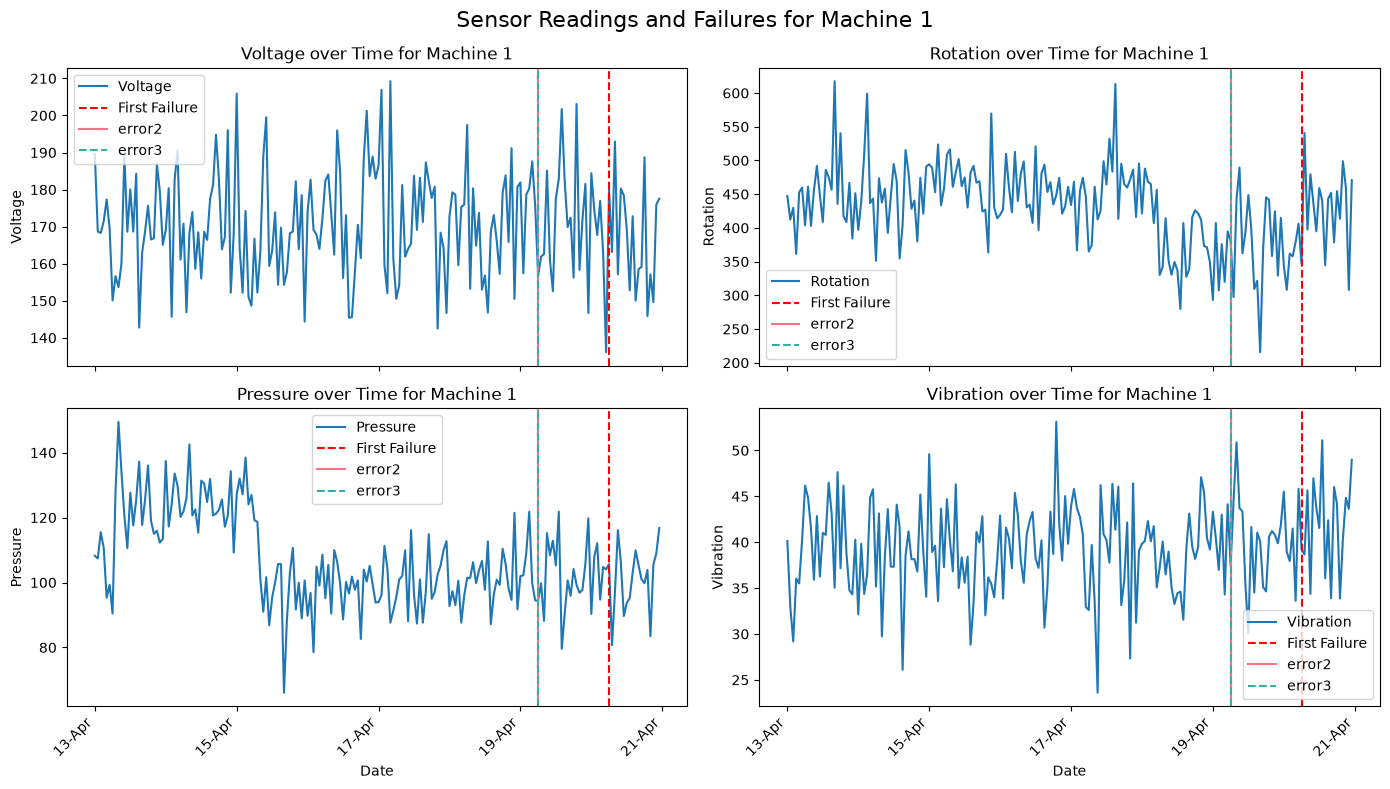

In [56]:
# Look up the first failures for machineID = 1
query_failure = ("select * from failures where machineID = 1 order by datetime asc limit 5")
df_failure = pd.read_sql_query(query_failure, connection)

# We pick the third row because the first two happened on the exact same date (two components broke together),
# and we want a clean 7-day window before the failure.
first_failure = df_failure['datetime'].iloc[2]

# Get sensor readings for Machine 1: 7 days before the failure and 1 day after
query_telemetry = """select * from telemetry
                     where machineID = ?
                     and datetime between date(?, '-7 day') and date(?, '+1 day')"""
df_telemetry = pd.read_sql_query(query_telemetry, connection, params = (1, first_failure, first_failure)) 

# Get the errors reported during that same 8-day window
query_error = """select datetime, errorID from errors
                 where machineID = ?
                 and datetime between date(?, '-7 day') and date(?, '+1 day')"""
df_error = pd.read_sql_query(query_error, connection, params = (1, first_failure, first_failure))

# Convert date columns to datetime format for plotting
df_telemetry['datetime'] = pd.to_datetime(df_telemetry['datetime'])
df_error['datetime'] = pd.to_datetime(df_error['datetime'])
first_failure = pd.to_datetime(first_failure)

sensors = [
    ('volt', 'Voltage'),
    ('rotate', 'Rotation'),
    ('pressure', 'Pressure'),
    ('vibration', 'Vibration')
]
error_types = sorted(df_error['errorID'].dropna().unique())
palette = sns.color_palette("husl", n_colors=len(error_types))
error_colors = dict(zip(error_types, palette))
linestyles = ['-', '--', '-.', ':']
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)

# Plot each sensor in its own subplot, marking errors and the actual failure
for ax, (column, label) in zip(axes.flat, sensors):
    ax.plot(df_telemetry['datetime'], df_telemetry[column], label=label)
    ax.axvline(first_failure, color='red', linestyle='--', label='First Failure')
    for error_type in error_types:
        error_dates = df_error.loc[
            df_error['errorID'] == error_type, 'datetime'
        ]

        for i, error_date in enumerate(error_dates):
            ax.axvline(
                x=error_date,
                color=error_colors[error_type],
                linestyle=linestyles[error_types.index(error_type) % len(linestyles)],
                alpha=1,
                label=error_type if i == 0 else '_nolegend_'
            )    
    ax.set_title(f'{label} over Time for Machine 1')
    ax.set_ylabel(label)
    ax.legend()
    ax.grid(False)
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%b'))

for ax in axes[1, :]:
    ax.set_xlabel('Date')

fig.autofmt_xdate(rotation=45)
plt.suptitle('Sensor Readings and Failures for Machine 1', fontsize=16)
plt.tight_layout()
fig.savefig('../img/machine1_failure.png')
plt.show()

In this chart, `error2` and `error3` happen at the exact same moment, which is why their vertical lines overlap. We can also see how noisy hourly sensor data is on its own, although rotation speed clearly drops right before the failure.

## 2. Feature Engineering: Rolling Sensor Windows (3h & 24h)
Since a single hourly reading has too much noise to tell us if a machine is about to break, we calculate **rolling averages and standard deviations** over the last **3 hours** (to catch sudden changes) and **24 hours** (to capture daily trends).

In [57]:
# Load all telemetry data sorted by machine and time
tel_diff_query = """select * from telemetry order by machineID, date(datetime) asc"""
df_tel_diff = pd.read_sql_query(tel_diff_query, connection)
df_tel_diff['datetime'] = pd.to_datetime(df_tel_diff['datetime'])
df_tel_diff = df_tel_diff.sort_values(['machineID', 'datetime']).reset_index(drop=True)
df_tel_diff.set_index('datetime', inplace=True)

sensors = ['volt', 'rotate', 'pressure', 'vibration']

# Compute 3-hour and 24-hour rolling mean and standard deviation per machine
roll_3h = df_tel_diff.groupby('machineID')[sensors].rolling('3h').agg(['mean', 'std']).reset_index(level=0, drop=True)
roll_3h.columns = [f"{sensor}_{stat}_3h" for sensor, stat in roll_3h.columns] # Names: volt_mean_3h, etc.
roll_24h = df_tel_diff.groupby('machineID')[sensors].rolling('24h').agg(['mean', 'std']).reset_index(level=0, drop=True)
roll_24h.columns = [f"{sensor}_{stat}_24h" for sensor, stat in roll_24h.columns]

df_tel_diff = pd.concat([df_tel_diff, roll_3h, roll_24h], axis=1)

## 3. Counting Recent Errors (Last 24h)
Next, instead of just checking if an error happened at that exact hour, we count **how many times each error type (`error1` to `error5`) occurred in the last 24 hours** for each machine.

In [58]:
# Load error logs and pivot so each error type becomes a column (0 or 1 per hour)
error_type_query = """select * from errors order by machineID, date(datetime) asc"""
df_error_type = pd.read_sql_query(error_type_query, connection)
df_error_type['datetime'] = pd.to_datetime(df_error_type['datetime'])
df_error_type = df_error_type.pivot_table(index=['machineID', 'datetime'], columns='errorID', aggfunc='size', fill_value=0)

# Merge with our telemetry table and sum errors over a 24-hour rolling window
df = pd.merge(df_tel_diff, df_error_type, how='left', on = ['machineID', 'datetime'])
df = df.sort_values(['machineID', 'datetime']).reset_index()
df.set_index('datetime', inplace=True)

new_columns = ['error1_count_24h', 'error2_count_24h', 'error3_count_24h', 'error4_count_24h', 'error5_count_24h']
columns_errors = ['error1', 'error2', 'error3', 'error4', 'error5']

df[new_columns] = df.groupby('machineID')[columns_errors].rolling('24h').sum().reset_index(level=0, drop=True)
df = df.drop(columns=columns_errors)
df[new_columns] = df[new_columns].fillna(0).astype(int)

## 4. Days Since Last Component Replacement
Older parts are more likely to fail. Here we calculate, for every hour, **how many days have passed since each of the four components (`comp1`-`comp4`) was last replaced**. We use `merge_asof` looking backwards so we also keep replacements from 2014.

In [2]:
# Load maintenance records and pivot so each component has its replacement date
maint_query = """select * from maint order by machineID, date(datetime) asc"""
df_maint = pd.read_sql_query(maint_query, connection)
df_maint['datetime'] = pd.to_datetime(df_maint['datetime'])
df_maint = df_maint.pivot_table(index=['machineID', 'datetime'], columns='comp', values = 'datetime', aggfunc='first')
df_maint = df_maint.reset_index()

# Forward-fill replacement dates per machine before matching them to hourly telemetry
components = ['comp1', 'comp2', 'comp3', 'comp4']
df_maint = df_maint.sort_values('datetime')
df_maint[components] = df_maint.groupby('machineID')[components].ffill()

df2 = pd.merge_asof(
    df.sort_values('datetime'),
    df_maint,
    on='datetime',
    by='machineID',
    direction='backward'
)
df2 = df2.sort_values(['machineID', 'datetime']).reset_index(drop=True)

# Calculate the difference in days between the current hour and the last replacement
for component in components:
    df2[f'{component}_days_since_last_maint'] = (df2['datetime'] - df2[component]).dt.days
    df2 = df2.drop(columns=[component])

NameError: name 'pd' is not defined

## 5. Adding Machine Model and Age
Now we add the general information for each machine: its **model type** (`model1` to `model4`) and **age** in years.

In [60]:
# Merge machine metadata (model and age)
machine_info_query = """select * from machines"""
df_machine_info = pd.read_sql_query(machine_info_query, connection)
data = pd.merge(df2, df_machine_info, how='left', on = ['machineID'])

## 6. Creating the Target Variable (`failure_next_24h`)
We now have all our input variables, so we just need the target column that our model will learn to predict: **will this machine fail in the next 24 hours, and which component will break?**
- Using `.bfill(limit=24)` per machine, we label the 24 hours prior to any failure with the component that breaks (`comp1`, `comp2`, `comp3`, or `comp4`).
- All normal operating hours are labelled as `'none'`.

In [74]:
# Load failures and keep the first failure if two components break at the exact same timestamp
df_failures = pd.read_sql_query("SELECT * FROM failures", connection)
df_failures['datetime'] = pd.to_datetime(df_failures['datetime'])
df_failures = df_failures.groupby(['machineID', 'datetime'])['failure'].first().reset_index()

# Merge with our hourly dataset and backfill 24 hours before each failure
data_failure = pd.merge(data, df_failures, on=['machineID', 'datetime'], how='left')
data_failure['failure_next_24h'] = data_failure.groupby('machineID')['failure'].bfill(limit=24)
data_failure['failure_next_24h'] = data_failure['failure_next_24h'].fillna('none')

data_failure = data_failure.drop(columns=['failure'])
data_failure['failure_next_24h'] = data_failure['failure_next_24h'].astype('category')

## 7. Saving the Final Dataset
Finally, we save the full table to `../data/features.csv` so we can load it directly in `model_training.ipynb` without having to run all these steps again.

In [75]:
# Export features dataset to CSV
data_failure.to_csv('../data/features.csv', index=False)

In [ ]:
# Close database connection
connection.close()